# Platform Sales Analysis
Answers the platform and regional sales questions (Q1–Q11) using `games_final.csv`.

Only rows that have sales numbers are used here (the VGChartz rows). Metacritic-only and Steam-only rows have no sales, so they're dropped for this notebook.

**Things to keep in mind for every chart:**
- All sales are **millions of game copies sold** (software), not consoles. The dataset has no console hardware sales.
- The sales data stops around 2016–2017, so newer platforms (PS4, Xbox One) are undercounted and Switch/PS5 aren't in it at all.
- PC sales are undercounted because VGChartz mostly tracks boxed retail copies, not digital Steam sales.
- The smallest sales number in the data is 0.01 (10,000 copies). Lots of games are tied at that amount.

## Setup

In [1]:
import pandas as pd
import seaborn as sns
import re

CLEAN = "../data/clean/"

BLUE = "#2a78d6"
REGION_COLORS = {"North America": "#2a78d6", "Europe": "#eb6834", "Japan": "#1baf7a", "Other": "#eda100"}

sns.set_theme(style="whitegrid", rc={"figure.figsize": (9, 6), "figure.dpi": 110, "legend.loc": "upper right"})

In [2]:
df = pd.read_csv(CLEAN + "games_final.csv", low_memory=False)
sales = df[df["global_sales"].notna()].copy()
print("All rows:", len(df))
print("Rows with sales:", len(sales))

All rows: 30526
Rows with sales: 16710


### Region columns
Rename the region columns once so every table and chart has readable labels.

In [3]:
REGIONS = {"na_sales": "North America", "eu_sales": "Europe", "jp_sales": "Japan", "other_sales": "Other"}
REGION_COLS = list(REGIONS.keys())

### Main platforms
Some platforms only have 1–12 games in the data (like PC-FX, Game Gear, 3DO). Change `TOP_N` to include more or fewer.

In [4]:
TOP_N = 20

platform_totals = sales.groupby("platform")["global_sales"].sum().sort_values(ascending=False)
MAIN = platform_totals.head(TOP_N).index.tolist()
main = sales[sales["platform"].isin(MAIN)]

print(MAIN)

['PS2', 'X360', 'PS3', 'Wii', 'DS', 'PS', 'GBA', 'PS4', 'PSP', 'PC', '3DS', 'XB', 'GB', 'NES', 'N64', 'SNES', 'GC', 'XOne', '2600', 'WiiU']


In [5]:
def title_to_file_name(string):
    no_parens = re.sub(r"\s*\([^)]*\)", "", string)
    return no_parens.replace(" ", "_").lower()

## Q1–Q3: Which platforms sold the most and least?

There's no console sales column, so Q1 and Q2 ("consoles sold") are answered using total game copies sold on each platform.

In [6]:
platform_summary = (
    sales.groupby(["platform", "platform_group"])
    .agg(games=("name", "size"), total_sales=("global_sales", "sum"), median_sales=("global_sales", "median"))
    .sort_values("total_sales", ascending=False)
    .reset_index()
)
platform_summary["total_sales"] = platform_summary["total_sales"].round(2)
platform_summary

,platform,platform_group,games,total_sales,median_sales
0,PS2,PlayStation,2159,1252.64,0.230
1,X360,Xbox,1261,970.38,0.280
2,PS3,PlayStation,1329,938.94,0.270
3,Wii,Nintendo,1320,908.13,0.190
4,DS,Nintendo,2151,806.87,0.110
5,PS,PlayStation,1197,730.68,0.260
6,GBA,Nintendo,822,318.50,0.165
7,PS4,PlayStation,393,314.23,0.200
8,PSP,PlayStation,1209,294.30,0.090
9,PC,PC,973,260.22,0.040


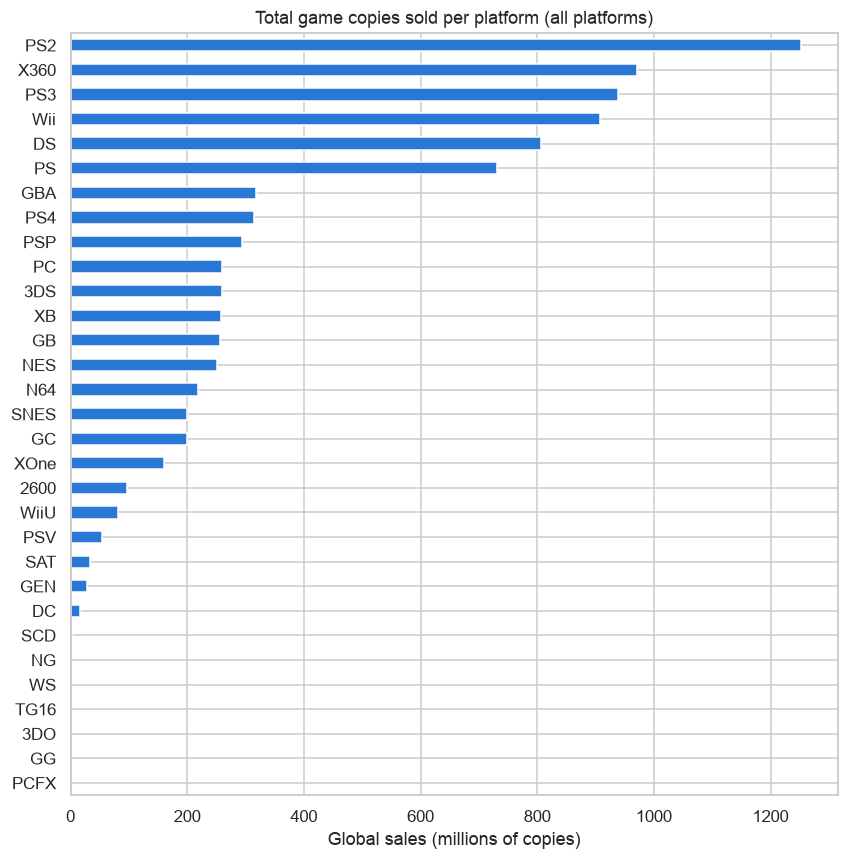

In [7]:
title = "Total game copies sold per platform (all platforms)"

platform_summary.sort_values("total_sales").plot.barh(
    x="platform", y="total_sales", color=BLUE, legend=False, figsize=(9, 9),
    title=title,
    xlabel="Global sales (millions of copies)", ylabel="",
).figure.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")

### Q1: Top 10 platforms

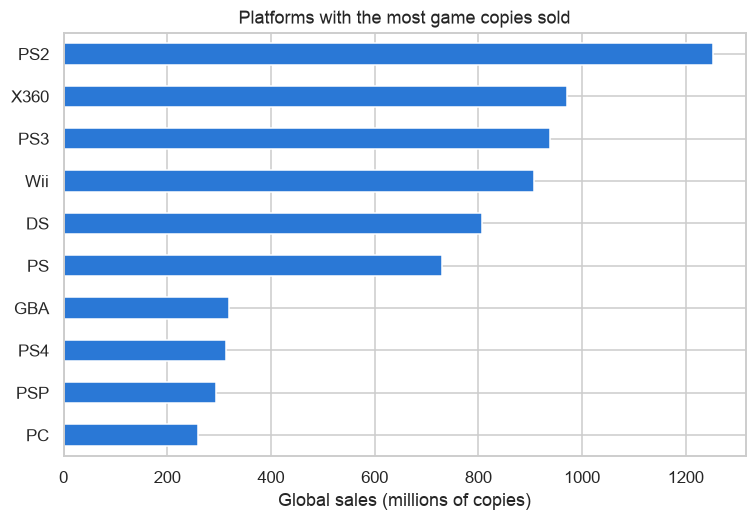

In [8]:
top10 = platform_summary.head(10)
title = "Platforms with the most game copies sold"

top10.sort_values("total_sales").plot.barh(
    x="platform", y="total_sales", color=BLUE, legend=False, figsize=(8, 5),
    title=title,
    xlabel="Global sales (millions of copies)", ylabel="",
).figure.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")

### Q2: Bottom 10 platforms
Most of these are platforms with very few games in the data, so the low total is partly because the data barely covers them. The `games` column shows how many games each one has.

,platform,platform_group,games,total_sales,median_sales
30,PCFX,Other,1,0.03,0.030
29,GG,Other,1,0.04,0.040
28,3DO,Other,3,0.10,0.020
27,TG16,Other,2,0.16,0.080
26,WS,Other,6,1.42,0.215
25,NG,Other,12,1.44,0.100
24,SCD,Other,6,1.87,0.065
23,DC,Other,52,15.97,0.135
22,GEN,Other,27,28.36,0.150
21,SAT,Other,173,33.59,0.120


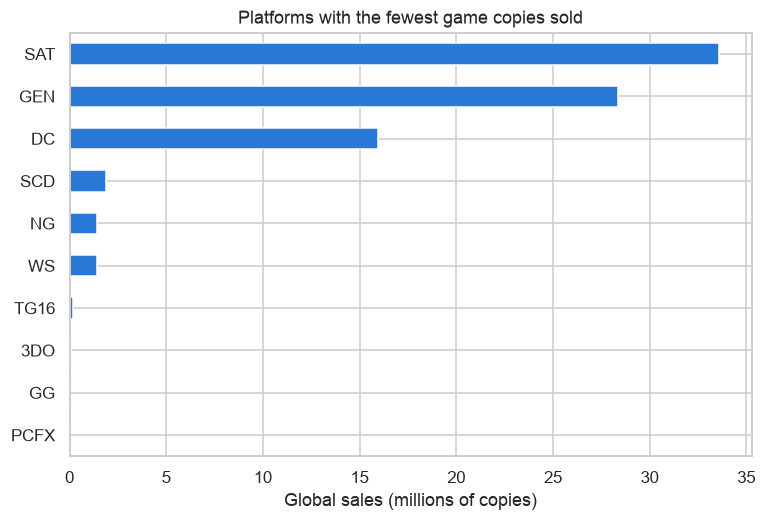

In [9]:
bottom10 = platform_summary.tail(10).sort_values("total_sales")
display(bottom10)
title = "Platforms with the fewest game copies sold"

bottom10.plot.barh(
    x="platform", y="total_sales", color=BLUE, legend=False, figsize=(8, 5),
    title=title,
    xlabel="Global sales (millions of copies)", ylabel="",
).figure.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")

### Q3: Copies sold by company
Same totals as above, added up by company (Sony, Microsoft, Nintendo, PC, Other).

,total_sales
platform_group,
PlayStation,3584.91
Nintendo,3499.56
Xbox,1388.08
PC,260.22
Other,180.06


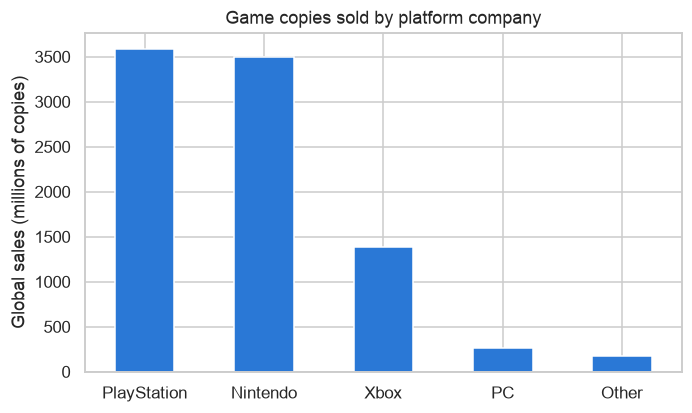

In [10]:
group_totals = sales.groupby("platform_group")["global_sales"].sum().sort_values(ascending=False)
display(group_totals.round(2).to_frame("total_sales"))
title = "Game copies sold by platform company"

group_totals.plot.bar(
    color=BLUE, rot=0, figsize=(7, 4),
    title=title,
    xlabel="", ylabel="Global sales (millions of copies)",
).figure.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")

## Q4 and Q9: Best selling games on each platform

In [11]:
def top_games(data, sales_col, n):
    return (
        data.sort_values(sales_col, ascending=False)
        .groupby("platform")
        .head(n)
        .sort_values(["platform", sales_col], ascending=[True, False])
    )

### Q9: Top-selling game on each platform (global)

In [12]:
best_global = top_games(main, "global_sales", 1)[["platform", "name", "year", "global_sales"]]
best_global = best_global.sort_values("global_sales", ascending=False).reset_index(drop=True)
best_global

,platform,name,year,global_sales
0,Wii,Wii Sports,2006.0,82.53
1,NES,Super Mario Bros.,1985.0,40.24
2,GB,Pokemon Red/Pokemon Blue,1996.0,31.37
3,DS,New Super Mario Bros.,2006.0,29.80
4,X360,Kinect Adventures!,2010.0,21.81
5,PS3,Grand Theft Auto V,2013.0,21.04
6,PS2,Grand Theft Auto: San Andreas,2004.0,20.81
7,SNES,Super Mario World,1990.0,20.61
8,GBA,Pokemon Ruby/Pokemon Sapphire,2002.0,15.85
9,PS4,Call of Duty: Black Ops 3,2015.0,14.63


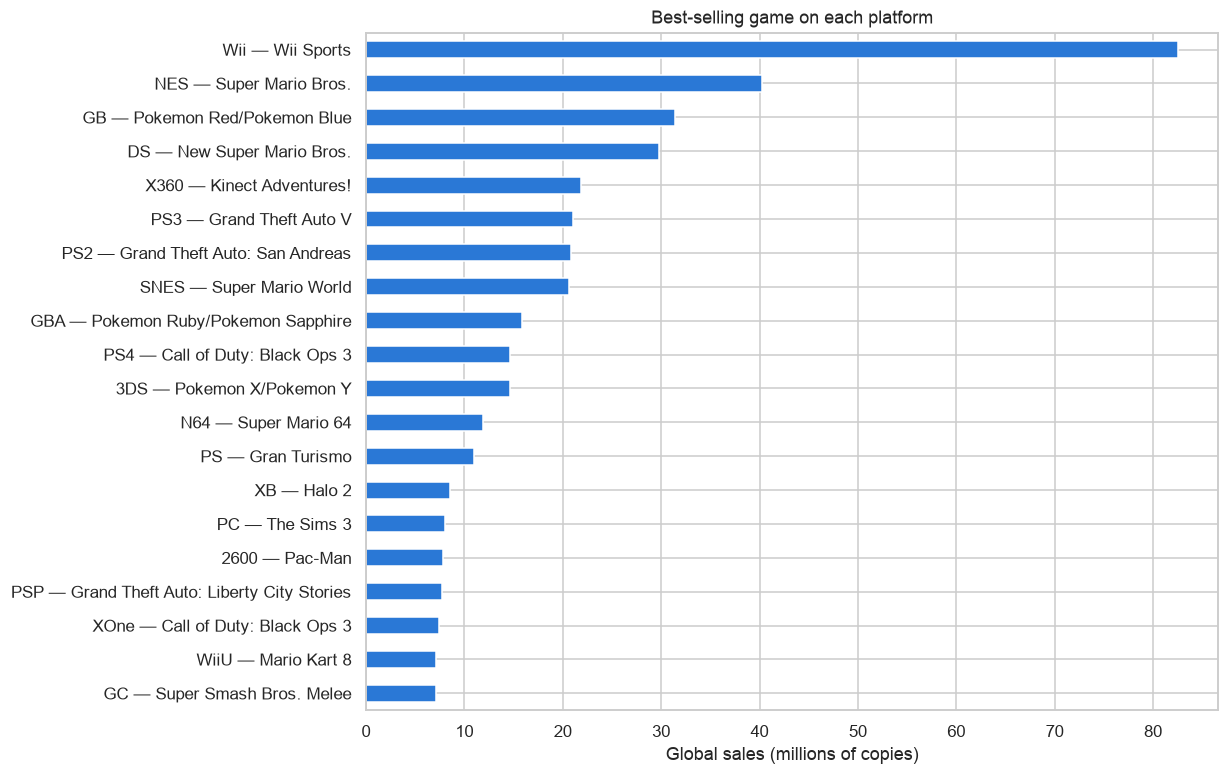

In [13]:
best_global["label"] = best_global["platform"] + " — " + best_global["name"]
title = "Best-selling game on each platform"

best_global.sort_values("global_sales").plot.barh(
    x="label", y="global_sales", color=BLUE, legend=False, figsize=(10, 8),
    title=title,
    xlabel="Global sales (millions of copies)", ylabel="",
).figure.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")

### Q4: Top 5 games on each platform
One small chart per platform. Each chart has its own x-axis scale, so compare the games *within* a platform, not bar lengths across platforms.

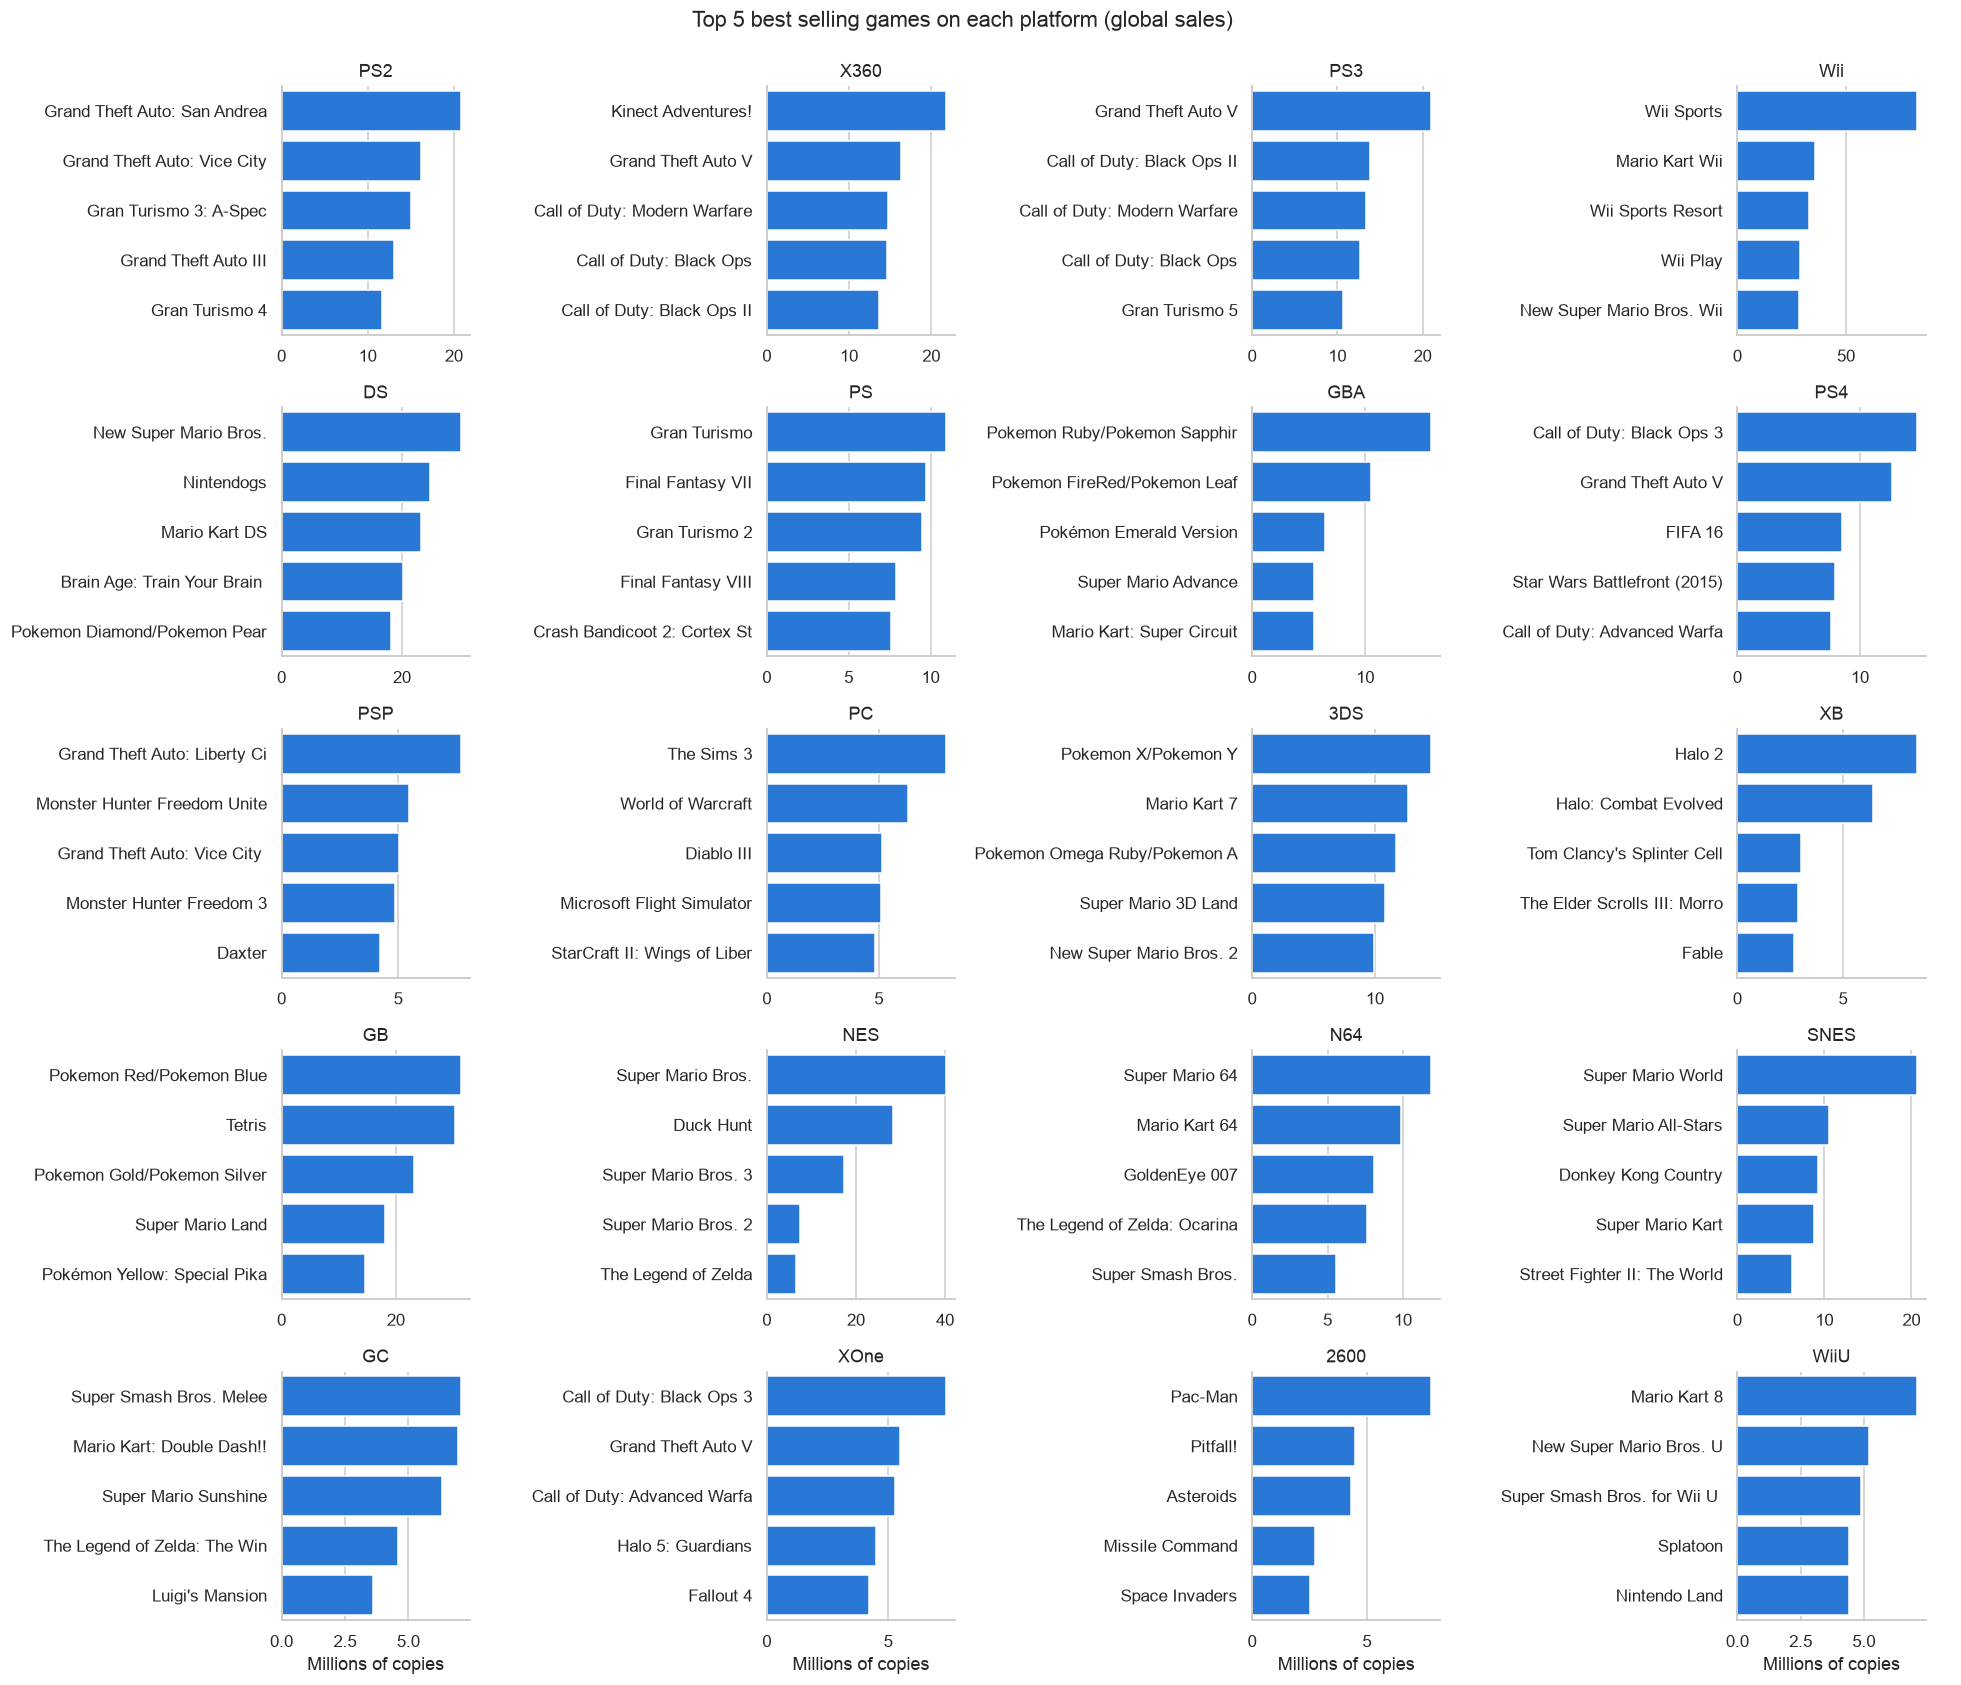

In [14]:
top5 = top_games(main, "global_sales", 5)
top5["short_name"] = top5["name"].str.slice(0, 28)
title = "Top 5 best selling games on each platform (global sales)"

g = sns.catplot(
    data=top5, x="global_sales", y="short_name", col="platform", col_order=MAIN, col_wrap=4,
    kind="bar", color=BLUE, saturation=1, sharex=False, sharey=False, height=3, aspect=1.5,
)
g.set_titles("{col_name}").set_axis_labels("Millions of copies", "")
g.figure.suptitle(title, y=1.02)
g.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")

In [15]:
# full table version of Q4 for the report
top5[["platform", "name", "year", "genre", "global_sales"]].reset_index(drop=True)

,platform,name,year,genre,global_sales
0,2600,Pac-Man,1982.0,Puzzle,7.81
1,2600,Pitfall!,1981.0,Platform,4.50
2,2600,Asteroids,1980.0,Shooter,4.31
3,2600,Missile Command,1980.0,Shooter,2.76
4,2600,Space Invaders,NaN,Shooter,2.53
...,...,...,...,...,...
95,XOne,Call of Duty: Black Ops 3,2015.0,Shooter,7.39
96,XOne,Grand Theft Auto V,2014.0,Action,5.48
97,XOne,Call of Duty: Advanced Warfare,2014.0,Shooter,5.27
98,XOne,Halo 5: Guardians,2015.0,Shooter,4.48


## Q5 & Q10: Worst-selling games on each platform

The lowest sales number in the data is 0.01 million, and many games on each platform are tied there. So there isn't one single "worst" game on most platforms. Instead this shows:
- the lowest sales amount on each platform
- how many games are tied at that amount
- a few example games from the tie

Also, VGChartz only lists games that sold at least ~10,000 copies, so games that sold less than that aren't in the data at all. The "worst" here actaully means worst among games in the data set

In [16]:
def worst_games(data, sales_col, examples=3):
    data = data[data[sales_col] > 0]
    rows = []
    
    for platform, group in data.groupby("platform"):
        low = group[sales_col].min()
        tied = group[group[sales_col] == low].sort_values("name")
        rows.append({
            "platform": platform,
            "lowest_sales": low,
            "games_tied": len(tied),
            "example_games": ", ".join(tied["name"].head(examples)),
        })
    
    return pd.DataFrame(rows)

### Q10: Worst-selling games on each platform

In [17]:
worst_global = worst_games(main, "global_sales").sort_values("games_tied", ascending=False).reset_index(drop=True)
worst_global

,platform,lowest_sales,games_tied,example_games
0,PC,0.01,103,"15 Days, Act of Aggression, Agatha Christie: P..."
1,DS,0.01,91,"Bakumatsu Koihana: Shinsengumi DS, Best Of Tes..."
2,PSP,0.01,89,"1/2 Summer +, Abunai: Koi no Sousa Shitsu, Acc..."
3,PS2,0.01,67,"Aa Megami-samaa, Alfa Romeo Racing Italiano, B..."
4,X360,0.01,32,"AKB1/48: Idol to Guam de Koishitara..., Advent..."
5,GBA,0.01,31,"Blackthorne, CT Special Forces 2: Back in the ..."
6,Wii,0.01,31,"Aladdin Magic Racer, Bomberman, Brave: The Vid..."
7,PS3,0.01,30,"Agarest Senki: Re-appearance, Akatsuki no Goei..."
8,3DS,0.01,27,"50 Classic Games, Aikatsu Stars! My Special Ap..."
9,XOne,0.01,20,"Agatha Christie's The ABC Murders, Assassin's ..."


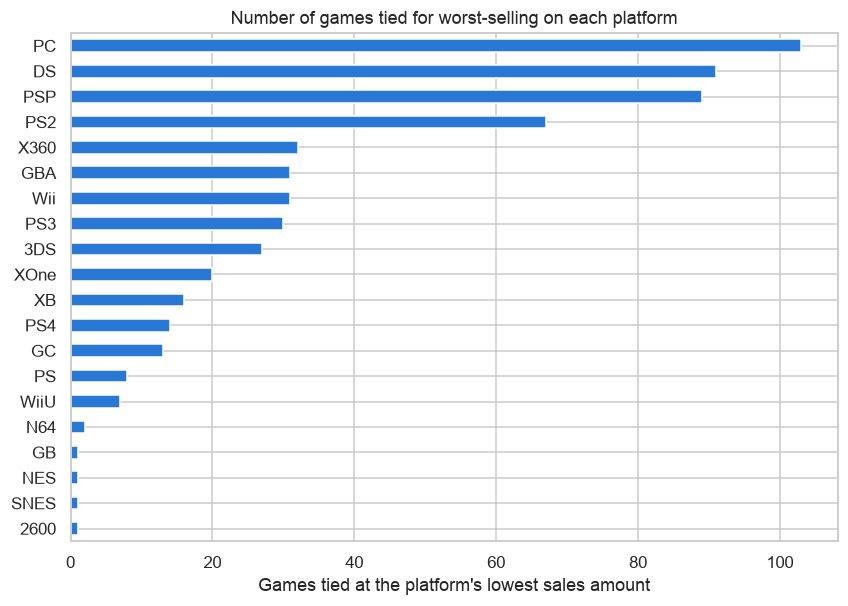

In [18]:
title = "Number of games tied for worst-selling on each platform"

worst_global.sort_values("games_tied").plot.barh(
    x="platform", y="games_tied", color=BLUE, legend=False, figsize=(9, 6),
    title=title,
    xlabel="Games tied at the platform's lowest sales amount", ylabel="",
).figure.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")

### Q5: Bottom 5 games on each platform
Because of ties, the "bottom 5" are picked alphabetically from the tied group. This is fine for examples, but not very meaningful. 

In [19]:
bottom5 = (
    main.sort_values(["global_sales", "name"])
    .groupby("platform")
    .head(5)
    .sort_values(["platform", "global_sales"])
)
bottom5[["platform", "name", "year", "genre", "global_sales"]].reset_index(drop=True)

,platform,name,year,genre,global_sales
0,2600,Super Baseball,1987.0,Sports,0.07
1,2600,Super Football,1987.0,Sports,0.08
2,2600,RealSports Volleyball,1981.0,Sports,0.13
3,2600,Krull,1982.0,Action,0.14
4,2600,Home Run,NaN,Sports,0.15
...,...,...,...,...,...
95,XOne,Agatha Christie's The ABC Murders,2016.0,Adventure,0.01
96,XOne,Assassin's Creed Chronicles,2016.0,Action,0.01
97,XOne,Darksiders: Warmastered Edition,2016.0,Action,0.01
98,XOne,Dead Rising,2016.0,Action,0.01


## Q6: Did any platforms sell more in other regions?

For each platform, find the share of its sales that came from each region. Platforms where North America is not the biggest region are the answer to the first part of Q6.

In [20]:
region_totals = main.groupby("platform")[REGION_COLS].sum().rename(columns=REGIONS)
region_share = region_totals.div(region_totals.sum(axis=1), axis=0)
region_totals["top_region"] = region_share.idxmax(axis=1)
region_totals["top_region_share"] = region_share.max(axis=1).round(2)

not_na = region_totals[region_totals["top_region"] != "North America"].sort_values("top_region_share", ascending=False)
print("Platforms where North America was not the biggest region:")
not_na

Platforms where North America was not the biggest region:


,North America,Europe,Japan,Other,top_region,top_region_share
platform,,,,,,
SNES,61.23,19.04,116.55,3.22,Japan,0.58
PC,94.53,142.38,0.17,22.36,Europe,0.55
PS4,108.74,141.09,16.00,48.35,Europe,0.45
3DS,83.49,61.48,100.67,13.36,Japan,0.39


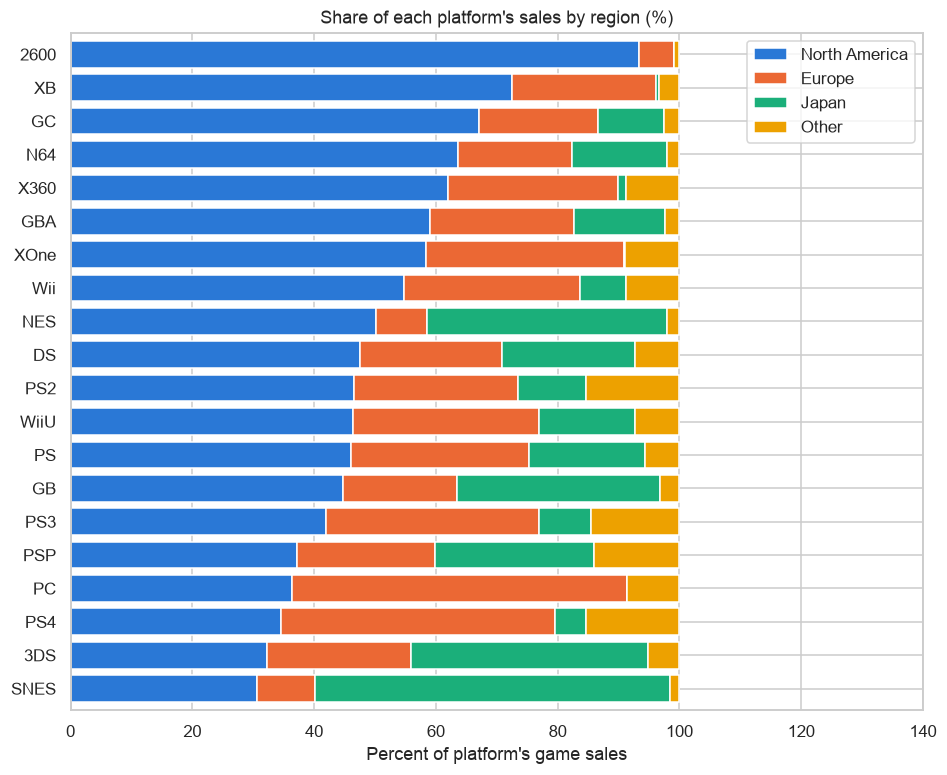

In [21]:
region_pct = region_share * 100
order = region_pct.sort_values("North America").index
title = "Share of each platform's sales by region (%)"

region_pct.loc[order].plot.barh(
    stacked=True, color=REGION_COLORS, width=0.8, figsize=(10, 8), xlim=(0, 140),
    title=title,
    xlabel="Percent of platform's game sales", ylabel="",
).figure.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")

### Q6 part 2: Which platforms sold the most in each region?

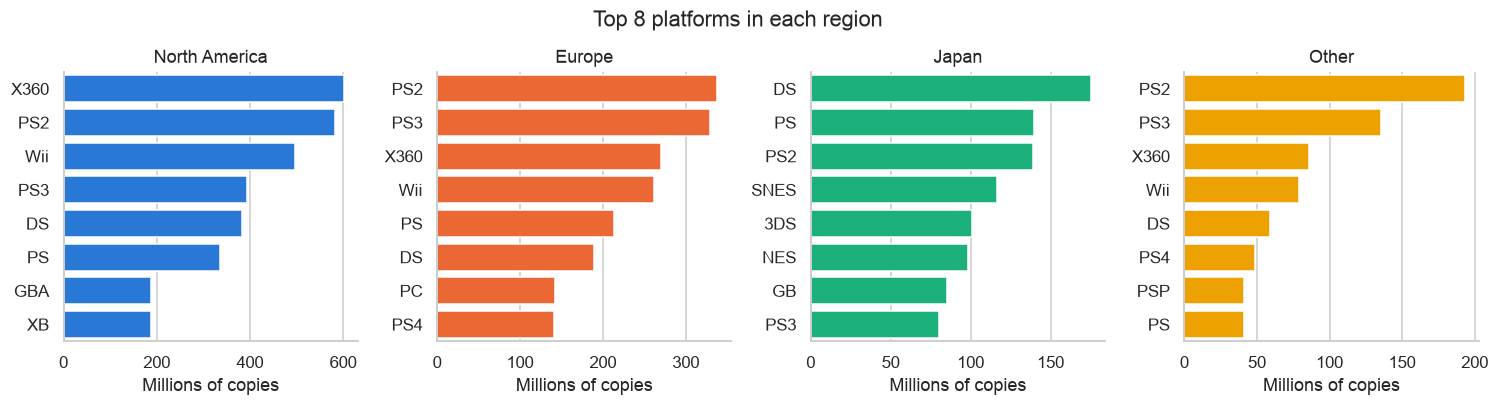

In [22]:
# long format: one row per platform + region, then keep the top 8 platforms in each region
by_region = region_totals[list(REGIONS.values())].reset_index().melt(id_vars="platform", var_name="region", value_name="sales")
top8 = by_region.sort_values("sales", ascending=False).groupby("region").head(8)
title = "Top 8 platforms in each region"

g = sns.catplot(
    data=top8, x="sales", y="platform", col="region", col_order=list(REGIONS.values()),
    hue="region", palette=REGION_COLORS, legend=False, saturation=1,
    kind="bar", sharex=False, sharey=False, height=3.5, aspect=1,
)
g.set_titles("{col_name}").set_axis_labels("Millions of copies", "")
g.figure.suptitle(title, y=1.05)
g.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")

## Q7: Best and worst games on those platforms, by region

For the platforms found in Q6, list the best-selling and worst-selling game in each region.

In [23]:
q6_platforms = not_na.index.tolist()
q6_data = main[main["platform"].isin(q6_platforms)]

def best_and_worst_by_region(data):
    rows = []
    for col, region in REGIONS.items():
        sold_there = data[data[col] > 0]
        best = top_games(sold_there, col, 1)
        worst = worst_games(sold_there, col, examples=2)
        for platform in sorted(data["platform"].unique()):
            b = best[best["platform"] == platform]
            w = worst[worst["platform"] == platform]
            rows.append({
                "platform": platform,
                "region": region,
                "best_game": b["name"].iloc[0] if len(b) else None,
                "best_sales": b[col].iloc[0] if len(b) else None,
                "worst_game(s)": w["example_games"].iloc[0] if len(w) else None,
                "worst_sales": w["lowest_sales"].iloc[0] if len(w) else None,
                "worst_tied": w["games_tied"].iloc[0] if len(w) else 0,
            })
    return pd.DataFrame(rows)

q7 = best_and_worst_by_region(q6_data).sort_values(["platform", "region"]).reset_index(drop=True)
q7

,platform,region,best_game,best_sales,worst_game(s),worst_sales,worst_tied
0,3DS,Europe,Pokemon X/Pokemon Y,4.19,"50 Classic Games, Beyblade Evolution",0.01,26
1,3DS,Japan,Animal Crossing: New Leaf,4.39,"Aikatsu Stars! My Special Appeal, Azure Strike...",0.01,21
2,3DS,North America,Pokemon X/Pokemon Y,5.28,"Adventure Time: The Secret of the Nameless, Az...",0.01,12
3,3DS,Other,Mario Kart 7,0.91,"Ace Combat: Assault Horizon Legacy, Adventure ...",0.01,101
4,PC,Europe,The Sims 3,6.42,"007: Quantum of Solace, 15 Days",0.01,158
5,PC,Japan,Half-Life,0.09,Half-Life 2,0.08,1
6,PC,North America,Half-Life,4.03,"007: Quantum of Solace, Age of Empires II: The...",0.01,106
7,PC,Other,World of Warcraft: Wrath of the Lich King,1.18,"18 Wheels of Steel: Extreme Trucker 2, 4 Elements",0.01,243
8,PS4,Europe,Grand Theft Auto V,6.31,"Agatha Christie's The ABC Murders, Arslan: The...",0.01,16
9,PS4,Japan,Metal Gear Solid V: The Phantom Pain,0.49,"Akiba's Trip: Undead & Undressed, Assassin's C...",0.01,28


In [24]:
q7_best = q7.pivot(index="platform", columns="region", values="best_game")[list(REGIONS.values())]

print("Best selling game per region on the Q6 platforms:")

q7_best

Best selling game per region on the Q6 platforms:


region,North America,Europe,Japan,Other
platform,,,,
3DS,Pokemon X/Pokemon Y,Pokemon X/Pokemon Y,Animal Crossing: New Leaf,Mario Kart 7
PC,Half-Life,The Sims 3,Half-Life,World of Warcraft: Wrath of the Lich King
PS4,Call of Duty: Black Ops 3,Grand Theft Auto V,Metal Gear Solid V: The Phantom Pain,Call of Duty: Black Ops 3
SNES,Super Mario World,Super Mario World,Super Mario Kart,Super Mario World


## Q8: Are there differences in sales between regions?

The heatmap shows each platform's regional share (same numbers as the Q6 chart). Darker is a bigger share.

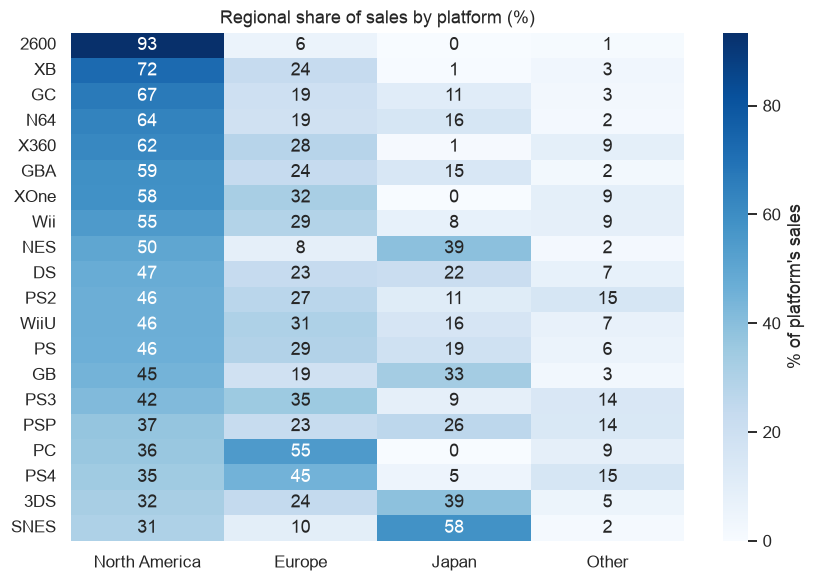

In [25]:
title = "Regional share of sales by platform (%)"

heatmap = sns.heatmap(region_pct.loc[order[::-1]], annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% of platform's sales"})
heatmap.set(title=title, xlabel="", ylabel="")
heatmap.figure.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")

### By company

,North America,Europe,Japan,Other
platform_group,,,,
Nintendo,50.4,22.3,21.8,5.5
Other,65.0,7.5,26.2,1.2
PC,36.4,54.9,0.1,8.6
PlayStation,43.0,30.8,13.2,13.0
Xbox,63.5,27.6,1.0,7.8


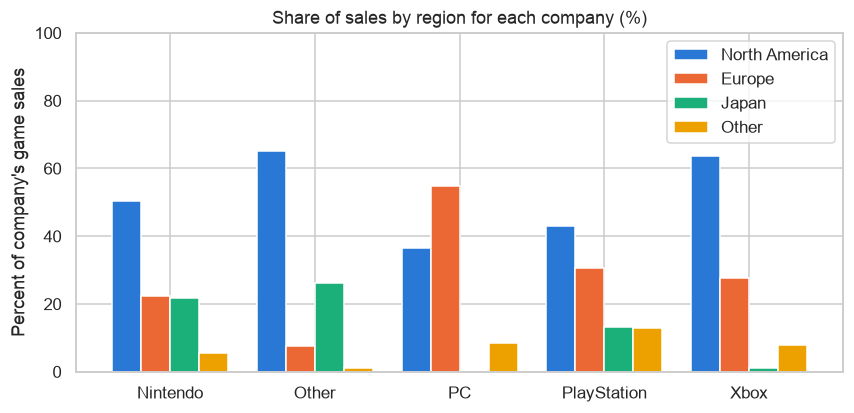

In [26]:
group_region = sales.groupby("platform_group")[REGION_COLS].sum().rename(columns=REGIONS)
group_pct = group_region.div(group_region.sum(axis=1), axis=0) * 100
display(group_pct.round(1))
title = "Share of sales by region for each company (%)"

group_pct.plot.bar(
    color=REGION_COLORS, width=0.8, rot=0, figsize=(9, 4), ylim=(0, 100),
    title=title,
    xlabel="", ylabel="Percent of company's game sales",
).figure.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")

### Biggest regional differences
Platforms ranked by how far their Japan share is from the overall Japan share.

In [27]:
overall_share = main[REGION_COLS].sum().rename(REGIONS) / main[REGION_COLS].sum().sum()
print("Overall share across all main platforms:")
display(overall_share.round(3).to_frame("share"))

diff = (region_share - overall_share).round(3)
diff.sort_values("Japan", ascending=False)

Overall share across all main platforms:


,share
North America,0.497
Europe,0.274
Japan,0.140
Other,0.089


,North America,Europe,Japan,Other
platform,,,,
SNES,-0.191,-0.179,0.443,-0.073
NES,0.005,-0.189,0.253,-0.068
3DS,-0.175,-0.036,0.249,-0.038
GB,-0.049,-0.087,0.193,-0.057
PSP,-0.126,-0.047,0.121,0.052
DS,-0.022,-0.039,0.077,-0.016
PS,-0.037,0.019,0.051,-0.033
WiiU,-0.033,0.032,0.018,-0.017
N64,0.139,-0.086,0.016,-0.069


## Q11: Best and worst game per platform in each region, and if they differ

Same as Q7, but for all main platforms. The same_as_global column says whether the regions best seller is the same game as the platform's global best seller.

In [28]:
q11 = best_and_worst_by_region(main)
global_best_name = best_global.set_index("platform")["name"]
q11 = q11[q11["best_game"].notna()]
q11["same_as_global"] = q11["best_game"] == q11["platform"].map(global_best_name)
q11 = q11.sort_values(["platform", "region"]).reset_index(drop=True)
q11

,platform,region,best_game,best_sales,worst_game(s),worst_sales,worst_tied,same_as_global
0,2600,Europe,Pac-Man,0.45,"Armor Ambush, Assault",0.01,25,True
1,2600,North America,Pac-Man,7.28,"Super Baseball, Super Football",0.07,2,True
2,2600,Other,Pac-Man,0.08,"Action Force, Adventure",0.01,49,True
3,3DS,Europe,Pokemon X/Pokemon Y,4.19,"50 Classic Games, Beyblade Evolution",0.01,26,True
4,3DS,Japan,Animal Crossing: New Leaf,4.39,"Aikatsu Stars! My Special Appeal, Azure Strike...",0.01,21,False
...,...,...,...,...,...,...,...,...
74,XB,Other,Tom Clancy's Splinter Cell,0.13,"2002 FIFA World Cup, 25 to Life",0.01,239,False
75,XOne,Europe,Grand Theft Auto V,2.19,"Assassin's Creed Chronicles, Assetto Corsa",0.01,22,False
76,XOne,Japan,Titanfall,0.04,"Battlefield: Hardline, Call of Duty: Advanced ...",0.01,15,False
77,XOne,North America,Call of Duty: Black Ops 3,4.59,"Agatha Christie's The ABC Murders, Arslan: The...",0.01,17,True


In [29]:
q11_best = q11.pivot(index="platform", columns="region", values="best_game")[list(REGIONS.values())]
q11_best.insert(0, "Global", global_best_name)
print("Best selling game on each platform, by region:")
q11_best

Best selling game on each platform, by region:


region,Global,North America,Europe,Japan,Other
platform,,,,,
2600,Pac-Man,Pac-Man,Pac-Man,NaN,Pac-Man
3DS,Pokemon X/Pokemon Y,Pokemon X/Pokemon Y,Pokemon X/Pokemon Y,Animal Crossing: New Leaf,Mario Kart 7
DS,New Super Mario Bros.,New Super Mario Bros.,Nintendogs,New Super Mario Bros.,New Super Mario Bros.
GB,Pokemon Red/Pokemon Blue,Tetris,Pokemon Red/Pokemon Blue,Pokemon Red/Pokemon Blue,Pokemon Red/Pokemon Blue
GBA,Pokemon Ruby/Pokemon Sapphire,Pokemon Ruby/Pokemon Sapphire,Pokemon Ruby/Pokemon Sapphire,Pokemon Ruby/Pokemon Sapphire,Pokemon Ruby/Pokemon Sapphire
GC,Super Smash Bros. Melee,Super Smash Bros. Melee,Mario Kart: Double Dash!!,Super Smash Bros. Melee,Super Smash Bros. Melee
N64,Super Mario 64,Super Mario 64,Super Mario 64,Mario Kart 64,Super Mario 64
NES,Super Mario Bros.,Super Mario Bros.,Super Mario Bros.,Super Mario Bros.,Dragon Warrior
PC,The Sims 3,Half-Life,The Sims 3,Half-Life,World of Warcraft: Wrath of the Lich King


In [30]:
different = q11[~q11["same_as_global"]][["platform", "region", "best_game", "best_sales"]]
print(f"Platform/region combos where the regional best seller is NOT the global best seller: {len(different)} of {len(q11)}")
different.reset_index(drop=True)

Platform/region combos where the regional best seller is NOT the global best seller: 26 of 79


,platform,region,best_game,best_sales
0,3DS,Japan,Animal Crossing: New Leaf,4.39
1,3DS,Other,Mario Kart 7,0.91
2,DS,Europe,Nintendogs,10.95
3,GB,North America,Tetris,23.20
4,GC,Europe,Mario Kart: Double Dash!!,1.77
5,N64,Japan,Mario Kart 64,2.23
6,NES,Other,Dragon Warrior,1.51
7,PC,Japan,Half-Life,0.09
8,PC,North America,Half-Life,4.03
9,PC,Other,World of Warcraft: Wrath of the Lich King,1.18


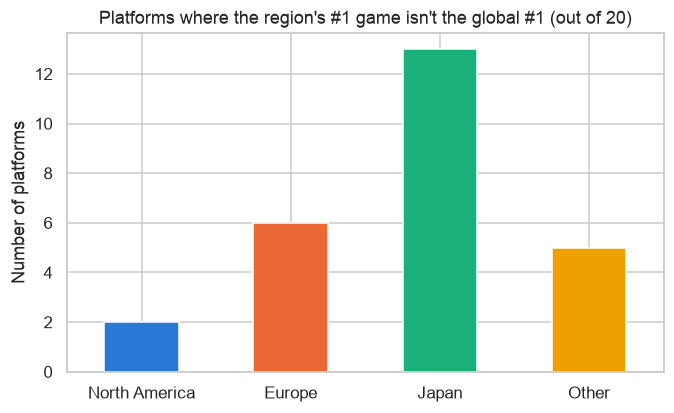

In [31]:
count_diff = (~q11["same_as_global"]).groupby(q11["region"]).sum().reindex(REGIONS.values())
title = f"Platforms where the region's #1 game isn't the global #1 (out of {len(MAIN)})"

count_diff.plot.bar(
    color=[REGION_COLORS[r] for r in count_diff.index], rot=0, figsize=(7, 4),
    title=title,
    xlabel="", ylabel="Number of platforms",
).figure.savefig(f'../figures/{title_to_file_name(title)}.png', dpi=200, bbox_inches="tight")